# EV Charging Infrastructure Optimization under Uncertain Demand

This notebook implements deterministic, two-stage stochastic, and chance-constrained models for charging capacity planning. For complete mathematical definitions, see [Mathematical formulation](../docs/model_formulation.md); for the saved numerical analysis, see [Results and interpretation](../results/README.md).

## Computational setup

The models use Pyomo and HiGHS, with NumPy and Matplotlib for scenarios and plots. The deterministic baseline and data/plotting helpers are imported from `utils.py`.

In [ ]:
# Import the deterministic benchmark, scenario generators, and plotting helpers.
from utils import (
    create_model,
    make_static_data,
    make_demand_scenarios,
    plot_instance,
    plot_solution,
)

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pyomo.environ as pyo

%matplotlib inline

highs_solver = pyo.SolverFactory('appsi_highs')  # MILP solver

## EV charging infrastructure planning

We select charging capacity among candidate locations in Manhattan, then allocate daily neighborhood demand to available chargers or account for unmet demand. The models differ in the timing and risk treatment of these decisions.

## Deterministic benchmark

The complete deterministic formulation—including indices, decision variables, objective and constraints—is documented in [`docs/model_formulation.md`](../docs/model_formulation.md#deterministic-model). The model used here is implemented in `utils.py`.

### Model and implementation

## Data and demand scenarios

Static instance parameters and sampled daily demand are loaded using the shared data utilities. The stored figures provide spatial context for the optimization problem.

In [4]:
static_data = make_static_data()

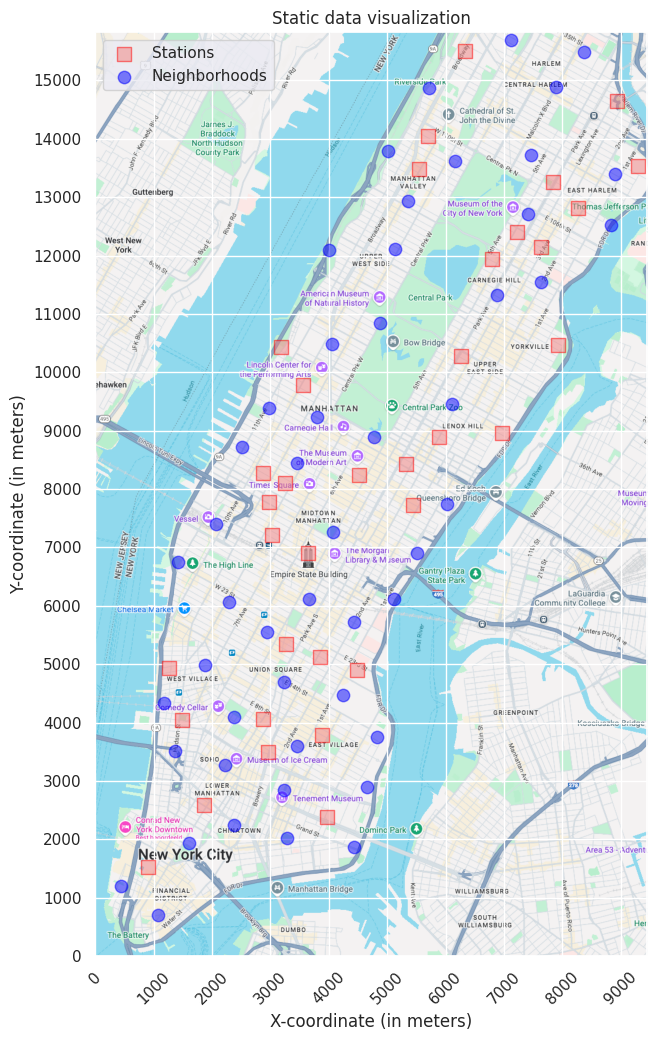

In [5]:
plot_instance(static_data);

In [5]:
demand_scenarios = make_demand_scenarios()
demand_scenarios;

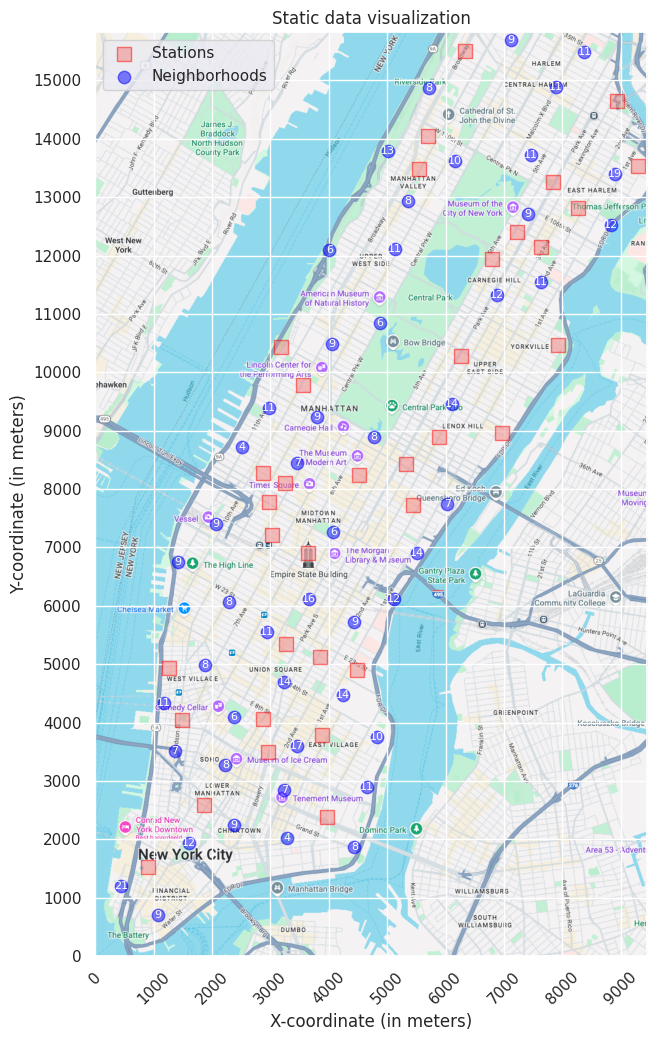

In [6]:
demand=demand_scenarios[0, :] # first demand scenario (say, Jan 1st)
plot_instance(static_data, demands=demand);

## Deterministic scenario benchmark

A separate deterministic optimization is solved for each of the 365 daily demand scenarios. The saved histogram and reported mean summarize the distribution of optimal costs when demand is known before station selection.

Average optimal cost deterministic model: 16857.055479452054


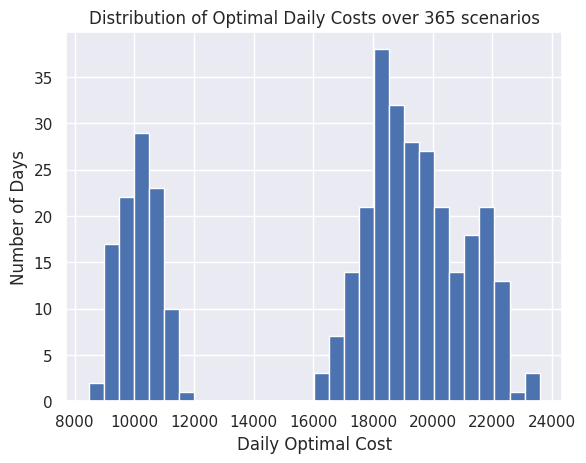

In [7]:
demand = demand_scenarios
obj_values = []

for i in range(demand_scenarios.shape[0]):
  daily_demands = demand_scenarios[i,:]
  model = create_model(
      stations = static_data.stations,
      neighborhoods = static_data.neighborhoods,
      fixed_costs = static_data.fixed_costs,
      travel_costs = static_data.travel_costs,
      penalty_unmet_demand = static_data.demand_penalty,
      max_chargers = static_data.max_chargers,
      demands = daily_demands
  )

  result = highs_solver.solve(model)

  obj_values.append(pyo.value(model.objective))

C_det = sum(obj_values) / len(obj_values)

print("Average optimal cost deterministic model:",C_det)

plt.hist(obj_values, bins = 30)
plt.xlabel("Daily Optimal Cost")
plt.ylabel("Number of Days")
plt.title("Distribution of Optimal Daily Costs over 365 scenarios")
plt.show()


## Two-stage stochastic optimization

The first-stage decision fixes charging-station capacity across all scenarios. Scenario-dependent second-stage variables represent allocation and unmet demand after demand is observed.

Demand is represented by 365 equally weighted scenarios. Charging capacity is a **first-stage** decision; assignment and unmet demand are **second-stage** decisions. The two-stage mathematical model is given in [`docs/model_formulation.md`](../docs/model_formulation.md#two-stage-stochastic-model).

### Extensive-form model

The finite-scenario extensive-form MILP uses a shared capacity decision across all scenarios. See [`docs/model_formulation.md`](../docs/model_formulation.md#extensive-form-milp) for the full objective and constraints.

### Pyomo implementation and stored solution

Optimal stochastic cost:  17107.43194520548


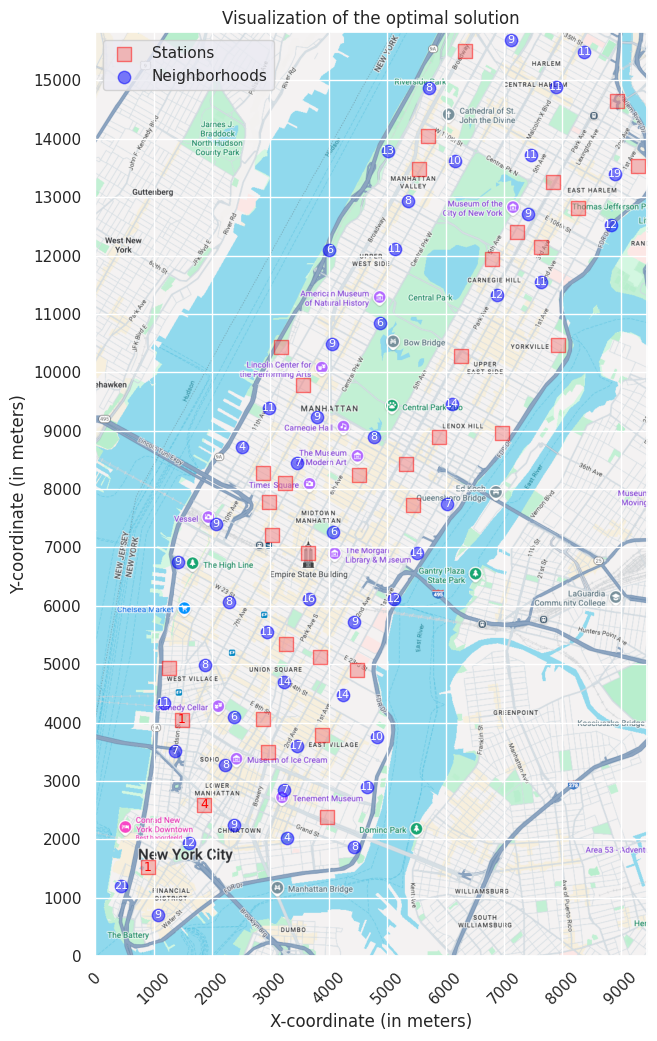

In [8]:
def create_stochastic_model(static_data, demand_scenarios):
  model = pyo.ConcreteModel()

  model.M = pyo.Set(initialize = static_data.stations)
  model.V = pyo.Set(initialize = static_data.neighborhoods)

  num_scenarios = demand_scenarios.shape[0]
  model.Omega = pyo.RangeSet(0, num_scenarios - 1)

  model.f = pyo.Param(model.M, initialize = lambda m, i: static_data.fixed_costs[i])
  model.c = pyo.Param(
      model.M, model.V,
      initialize = lambda m, i,j: static_data.travel_costs[i,j]
  )
  model.p = pyo.Param(initialize = static_data.demand_penalty)
  model.K = pyo.Param(model.M, initialize = lambda m, i: static_data.max_chargers[i])

  def demand_init(m,j,w):
    return float(demand_scenarios[w,j])

  model.d = pyo.Param(model.V, model.Omega, initialize = demand_init)

  model.x = pyo.Var(model.M, domain = pyo.NonNegativeIntegers)
  model.y = pyo.Var(model.M, model.V, model.Omega, domain = pyo.NonNegativeIntegers)
  model.u = pyo.Var(model.V, model.Omega, domain = pyo.NonNegativeIntegers)

  @model.Expression()
  def total_fixed_cost(m):
    return sum(m.f[i]*m.x[i] for i in m.M)

  @model.Expression()
  def expected_operating_cost(m):
    n_omega = len(m.Omega)
    travel = sum(m.c[i,j]*m.y[i,j,w] for i in m.M for j in m.V for w in m.Omega)
    penalty = sum(m.p*m.u[j,w] for j in m.V for w in m.Omega)

    return (travel + penalty)/n_omega

  @model.Objective(sense = pyo.minimize)
  def objective(m):
    return m.total_fixed_cost + m.expected_operating_cost

  @model.Constraint(model.V, model.Omega)
  def demand_equation(m,j,w):
    return sum(m.y[i,j,w] for i in m.M) + m.u[j,w] == m.d[j,w]

  @model.Constraint(model.M,model.Omega)
  def charging_station_capacity(m,i,w):
    return sum(m.y[i,j,w] for j in m.V) <= m.x[i]

  @model.Constraint(model.M)
  def max_chargers_per_station(m,i):
    return m.x[i] <= m.K[i]


  return model


model_sto = create_stochastic_model(static_data, demand_scenarios)
result = highs_solver.solve(model_sto)
result.solver.termination_condition

C_sto = pyo.value(model_sto.objective)

print("Optimal stochastic cost: ", C_sto)

build_decision = {
    i: int(pyo.value(model_sto.x[i]))
    for i in model_sto.M
    if pyo.value(model_sto.x[i]) > 1e-6
}

demand = demand_scenarios[0,:]
plot_solution(static_data, build_decisions, demand = demand)


**Saved stochastic objective:** $C_{sto}=17,107.43194520548$.

### Deterministic versus stochastic cost

**Comparison $C_{det}$ and $C_{sto}$**

The stochastic optimal cost $C_{sto}$ is higher than the average deterministic cost $C_{det}$, which was expected.

The deterministic model is solved seperately for each demand scenario, which means that the placement of charging stations is optimized after the demand is known. In other words, the model has perfect information and can adapt the decisions to each specific realization of demand. When we average the resulting daily optimal costs we obtain a value that is optimistic and therefore low.

On the other hand, in the stochastic model the number of charging stations must be decided before the demand is realized. These first-stage decisions must perform well across all scenarios, inlcuding days with usually high or uneven demand. As a result, the model may build more stations or place them more conservatively, increasing the total expected cost.

Therefore, $C_{sto}$ accounts for uncertainty in a realistic way, while $C_{det}$ implicity assumes perfect foresight. This loss of flexibility explains why the stochastic solution is more expensive on average.



## Chance-Constrained Capacity Planning

This variant focuses on aggregate charging capacity. It uses a risk tolerance $\epsilon$ and a demand-deviation tolerance $\Delta$ to control acceptable deviations from observed aggregate demand scenarios.

### Aggregated daily demand

In [9]:
aggregate_demands = demand_scenarios.sum(axis=1)

### Scenario-wise mixed-integer formulation

The aggregate-demand model minimizes construction cost subject to scenario-wise mismatch limits. The **exact big-M formulation implemented here** and the distinction from a joint chance constraint are explained in [`docs/model_formulation.md`](../docs/model_formulation.md#chance-constrained-capacity-model).

### Pyomo model and stored result

In [10]:
def create_chance_constraint_model(static_data, aggregate_demands, Delta, epsilon, M_big):
  model = pyo.ConcreteModel()

  model.M = pyo.Set(initialize = static_data.stations)
  model.Omega = pyo.RangeSet(0, len(aggregate_demands)-1)

  model.f = pyo.Param(model.M, initialize = lambda m, i: static_data.fixed_costs[i])
  model.K = pyo.Param(model.M, initialize = lambda m, i: static_data.max_chargers[i])
  model.D = pyo.Param(model.Omega, initialize = lambda m, w: float(aggregate_demands[w]))

  model.x = pyo.Var(model.M, domain=pyo.NonNegativeIntegers)
  model.z_plus = pyo.Var(model.Omega, domain=pyo.Binary)
  model.z_minus = pyo.Var(model.Omega, domain=pyo.Binary)

  @model.Objective(sense=pyo.minimize)
  def objective(m):
    return sum(m.f[i]*m.x[i] for i in m.M)

  @model.Constraint(model.Omega)
  def upper_mismatch(m,w):
    return m.D[w]-sum(m.x[i] for i in m.M) <= Delta + M_big*m.z_plus[w]

  @model.Constraint(model.Omega)
  def lower_mismatch(m,w):
    return -m.D[w] + sum(m.x[i] for i in m.M) <= Delta + M_big*m.z_minus[w]


  @model.Constraint()
  def upper_chance(m):
    return sum(m.z_plus[w] for w in m.Omega) <= epsilon*len(m.Omega)

  @model.Constraint()
  def lower_chance(m):
    return sum(m.z_minus[w] for w in m.Omega) <= epsilon*len(m.Omega)

  @model.Constraint(model.M)
  def max_chargers(m,i):
    return m.x[i] <= m.K[i]


  return model

epsilon = 0.2
Delta = 150
M_big = max(aggregate_demands) + sum(static_data.max_chargers)

model_cc = create_chance_constraint_model(
    static_data,
    aggregate_demands,
    Delta,
    epsilon,
    M_big
)

result = highs_solver.solve(model_cc, load_solutions=False)

if result.solver.termination_condition == pyo.TerminationCondition.optimal:
  model_cc.solutions.load_from(result)
  obj_value = pyo.value(model_cc.objective)
  print("Optimal objective value", obj_value)
else:
  print("The model is infeasible.")

Optimal objective value 4529.0


With $\epsilon=0.2$ and $\Delta=150$, the saved optimal installation-cost objective is **4,529.0**.

### Sensitivity analysis

<>:52: SyntaxWarning: invalid escape sequence '\s'
<>:52: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-3052981634.py:52: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel('Total capacity $\sum_i x_i$')


Model infeasible for epsilon=0.00
Model infeasible for epsilon=0.10
Model feasible for epsilon=0.20
Model feasible for epsilon=0.30
Model feasible for epsilon=0.40
Model feasible for epsilon=0.50
Model feasible for epsilon=0.60
Model feasible for epsilon=0.70
Model feasible for epsilon=0.80
Model feasible for epsilon=0.90
Model feasible for epsilon=1.00


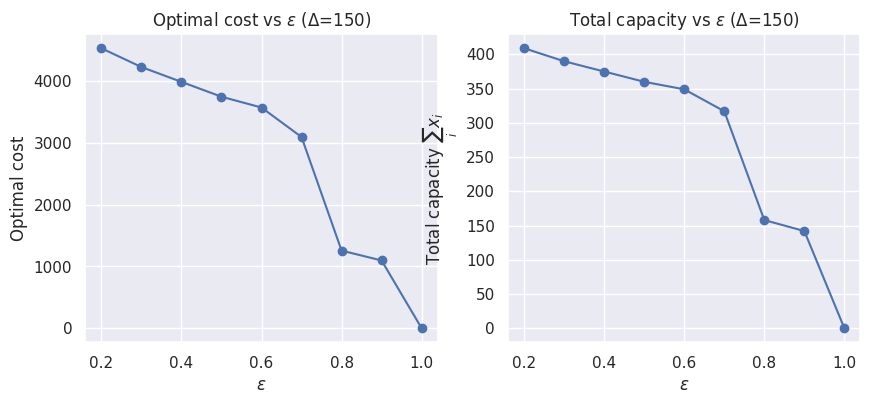

Model infeasible for Delta=70
Model infeasible for Delta=80
Model infeasible for Delta=90
Model infeasible for Delta=100
Model infeasible for Delta=110
Model infeasible for Delta=120
Model infeasible for Delta=130
Model feasible for Delta=140
Model feasible for Delta=150
Model feasible for Delta=160
Model feasible for Delta=170
Model feasible for Delta=180
Model feasible for Delta=190
Model feasible for Delta=200
Model feasible for Delta=210
Model feasible for Delta=220
Model feasible for Delta=230
Model feasible for Delta=240
Model feasible for Delta=250
Model feasible for Delta=260
Model feasible for Delta=270
Model feasible for Delta=280
Model feasible for Delta=290
Model feasible for Delta=300


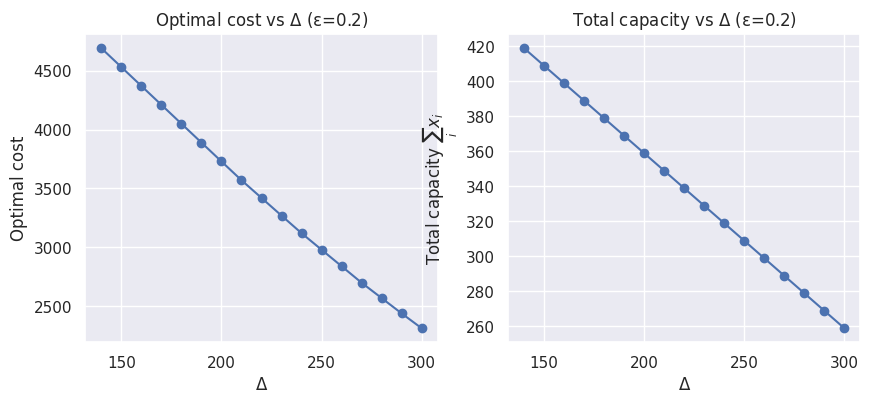

In [11]:
Delta_fixed = 150
eps_values = np.linspace(0,1,11)

eps_objectives = []
eps_capacities = []
eps_feasible = []

for eps in eps_values:
  model = create_chance_constraint_model(
      static_data,
      aggregate_demands,
      Delta_fixed,
      eps,
      M_big
  )
  result = highs_solver.solve(model, load_solutions=False)

  if result.solver.termination_condition == pyo.TerminationCondition.optimal:
    print(f"Model feasible for epsilon={eps:.2f}")
    model.solutions.load_from(result)
    obj = pyo.value(model.objective)
    total_x = sum(pyo.value(model.x[i]) for i in model.M)

    eps_objectives.append(obj)
    eps_capacities.append(total_x)
    eps_feasible.append(True)

  else:
    print(f"Model infeasible for epsilon={eps:.2f}")
    eps_objectives.append(None)
    eps_capacities.append(None)
    eps_feasible.append(False)


feps = [e for e, ok in zip(eps_values,eps_feasible) if ok]
fobj = [o for o, ok in zip(eps_objectives,eps_feasible) if ok]
fcap = [c for c, ok in zip(eps_capacities,eps_feasible) if ok]

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(feps, fobj, marker='o')
plt.xlabel(r'$\varepsilon$')
plt.ylabel('Optimal cost')
plt.title(r'Optimal cost vs $\varepsilon$ (Δ=150)')
plt.grid(True)


plt.subplot(1,2,2)
plt.plot(feps, fcap, marker='o')
plt.xlabel(r'$\varepsilon$')
plt.ylabel('Total capacity $\sum_i x_i$')
plt.title(r'Total capacity vs $\varepsilon$ (Δ=150)')
plt.grid(True)
plt.show()

eps_fixed = 0.2
Delta_values = list(range(70,301,10))

Delta_objectives = []
Delta_capacities = []
Delta_feasible = []

for Delta in Delta_values:
  model = create_chance_constraint_model(
      static_data,
      aggregate_demands,
      Delta,
      eps_fixed,
      M_big
  )

  result =highs_solver.solve(model, load_solutions=False)

  if result.solver.termination_condition == pyo.TerminationCondition.optimal:
    print(f"Model feasible for Delta={Delta}")
    model.solutions.load_from(result)

    obj = pyo.value(model.objective)
    total_x = sum(pyo.value(model.x[i]) for i in model.M)

    Delta_objectives.append(obj)
    Delta_capacities.append(total_x)
    Delta_feasible.append(True)

  else:
    print(f"Model infeasible for Delta={Delta}")
    Delta_objectives.append(None)
    Delta_capacities.append(None)
    Delta_feasible.append(False)


fDelta = [d for d, ok in zip(Delta_values, Delta_feasible) if ok]
fobj_D = [o for o, ok in zip(Delta_objectives, Delta_feasible) if ok]
fcap_D = [c for c, ok in zip(Delta_capacities, Delta_feasible) if ok]

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(fDelta, fobj_D, marker='o')
plt.xlabel(r'$\Delta$')
plt.ylabel('Optimal cost')
plt.title(r'Optimal cost vs $\Delta$ (ε=0.2)')
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(fDelta, fcap_D, marker='o')
plt.xlabel(r'$\Delta$')
plt.ylabel(r'Total capacity $\sum_i x_i$')
plt.title(r'Total capacity vs $\Delta$ (ε=0.2)')
plt.grid(True)
plt.show()

**Varying $\epsilon$ with fixed $\Delta=150$**

From the results we observe that both the optimal cost and the total installed capacity decreases as $\epsilon$ increases. For small $\epsilon$, the model is higly conservative. The mismatch constraint must be satisfied in almost all scenarios. This leads to high installed capacity and high cost, and for $\epsilon \in [0,0.1]$ the problem becomes infrasible, meaning it is impossible to guarantee such a strict service level with $\Delta=150$. As $\epsilon$ increases, more scenarios are allowed to violate the constraint, which relaxes the feasible region and allows the optimizer to reduce the number of chargers installed. In the extreme case $\epsilon=1$ all scenarios may violate the constraint and the optimal solution installs no chargers rsulting in zero cost.
This illustrates the trade-off between cost and reliability: greater risk tolerance leads to cheaper but less robust solutions.

**Varying $\Delta$ with dfixed $\epsilon=0.2$**

In this step, $\Delta$ is varied and $\epsilon$ is fixed. $\Delta$ represents the maximum tolerated mismatch between total demand and total capacity. Small values of $\Delta$ impose a very strict requirement on how closely capacity must track demand in most scenarios. As a result, for $\Delta \leq 130$ the problem is infeasible, even though violations are allowed in 20% of the scenarios.

When $\Delta$ becomes sufficiently large $(\Delta\geq 140)$, the chance constraints can be satisfied and the problem becomes feasible. As $\Delta$ increases further, the constraints become progressively looser, which allows the optimizer to reduce total capacity and cost. This leads to a monotonic decrease in both objective value and the installed capacity.

This behavior illustrates that chance constriants control the size of acceptable violations, while $\epsilon$ controls how often violations are allowed.




## Conclusions

The deterministic benchmark optimizes charging capacity separately for each daily demand scenario, while the two-stage stochastic model chooses one capacity plan before demand is observed. The comparison illustrates the additional cost of making infrastructure decisions under uncertainty.

The chance-constrained model examines the relationship between installation cost, total capacity, risk tolerance ($\epsilon$), and permissible demand mismatch ($\Delta$). Its saved sensitivity plots show how these choices affect feasibility and optimized capacity.